# 03 · Descarga de imágenes GOES-Este (ABI)
**Datos tipo SUPERFICIE**, una imagen por hora:

| Canal | Longitud de onda | Resolución | Para qué | Dominio | Horas |
|---|---|---|---|---|---|
| 13 | 10,3 µm (infrarrojo) | 2 km | Temperatura de brillo → **SCM** | amplio (4–15 °N, 80–68 °O) | 24 h |
| 2 | 0,64 µm (visible) | 0,5 km → 2 km | Reflectancia → **irradiancia** | Magdalena | 6–18 h local |

**Fuente:**
- Buckets públicos de NOAA en AWS (`noaa-goes16`, `noaa-goes19`), sin registro.
- Se leen **solo los bloques del dominio**, no el disco completo.
- GOES-16 fue GOES-Este hasta el 7 de abril de 2025; desde entonces es GOES-19. El cambio es automático.

**Consejos:**
- Primero ejecuta la **prueba de una hora** (sección 2) y mira las imágenes.
- Si la descarga se interrumpe, vuelve a ejecutar la celda: **salta los días ya descargados**.

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import re
from datetime import datetime, timedelta
import numpy as np
import xarray as xr
import s3fs
import matplotlib.pyplot as plt
import config as C
from utils import indices_dominio, latlon_subconjunto

fs = s3fs.S3FileSystem(anon=True)
_cache_idx = {}

## 1. Funciones de lectura

In [4]:
def satelite(dt):
    return ("noaa-goes19", "G19") if dt >= C.CAMBIO_GOES19 else ("noaa-goes16", "G16")


def archivo_hora(dt, canal):
    """Archivo del canal pedido cuyo escaneo empieza más cerca de la hora en punto."""
    bucket, _ = satelite(dt)
    ruta = f"{bucket}/ABI-L2-CMIPF/{dt:%Y}/{dt:%j}/{dt:%H}/"
    try:
        arch = [a for a in fs.ls(ruta) if re.search(rf"M\dC{canal:02d}_", a)]
    except FileNotFoundError:
        return None
    if not arch:
        return None
    minuto = lambda a: int(re.search(r"_s\d{9}(\d{2})", a).group(1))
    return sorted(arch, key=minuto)[0]


def leer(dt, canal, dominio, factor=1):
    """Lee el subconjunto del dominio. factor=4 promedia el canal 2 (0,5 km) a 2 km."""
    a = archivo_hora(dt, canal)
    if a is None:
        return None
    with fs.open(a, "rb") as f, xr.open_dataset(f, engine="h5netcdf") as ds:
        clave = (satelite(dt)[1], canal, dominio)
        if clave not in _cache_idx:
            if factor == 1:
                _cache_idx[clave] = indices_dominio(ds, dominio)
            else:   # índices anidados en la malla de 2 km del canal 13
                y0, y1, x0, x1 = _cache_idx[(satelite(dt)[1], 13, dominio)]
                _cache_idx[clave] = (y0 * factor, y1 * factor, x0 * factor, x1 * factor)
        y0, y1, x0, x1 = _cache_idx[clave]
        sub = ds.isel(y=slice(y0, y1), x=slice(x0, x1))
        cmi = sub["CMI"].values.astype("float32")
        if factor > 1:
            ny, nx = cmi.shape[0] // factor, cmi.shape[1] // factor
            cmi = np.nanmean(cmi[:ny * factor, :nx * factor].reshape(ny, factor, nx, factor), axis=(1, 3))
            sub = sub.isel(y=slice(0, None, factor), x=slice(0, None, factor)).isel(y=slice(0, ny), x=slice(0, nx))
        lat, lon = latlon_subconjunto(sub)
    return cmi, lat, lon


def asegurar_indices_c13(dt, dominio):
    if (satelite(dt)[1], 13, dominio) not in _cache_idx:
        leer(dt, 13, dominio)

## 2. Prueba con UNA hora
Cambia la fecha si quieres ver otro momento. A las 20 UTC son las 3 p. m. hora local.

Canal 13: (593, 662) Tb mín = 191 K
Canal 2 : (161, 99) reflectancia media = 0.28


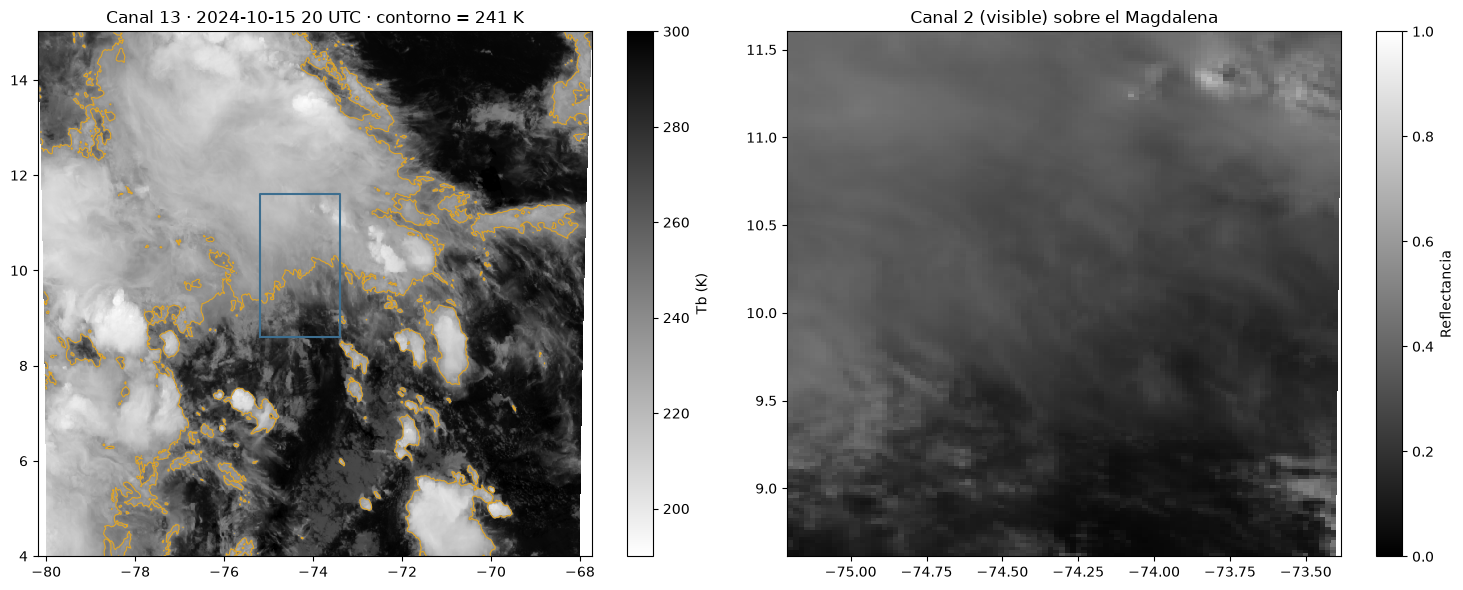

In [5]:
dt_prueba = datetime(2024, 10, 15, 20)

tb, lat_tb, lon_tb = leer(dt_prueba, 13, C.DOM_SEGUIMIENTO)
asegurar_indices_c13(dt_prueba, C.DOM_ANALISIS)
vis, lat_v, lon_v = leer(dt_prueba, 2, C.DOM_ANALISIS, factor=4)
print("Canal 13:", tb.shape, f"Tb mín = {np.nanmin(tb):.0f} K")
print("Canal 2 :", vis.shape, f"reflectancia media = {np.nanmean(vis):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
m = axs[0].pcolormesh(lon_tb, lat_tb, tb, cmap="gray_r", shading="auto", vmin=190, vmax=300)
axs[0].contour(lon_tb, lat_tb, tb, levels=[C.TB_ESCUDO_K], colors="#E0A526", linewidths=0.8)
plt.colorbar(m, ax=axs[0], label="Tb (K)")
axs[0].set_title(f"Canal 13 · {dt_prueba:%Y-%m-%d %H} UTC · contorno = {C.TB_ESCUDO_K:.0f} K")
m = axs[1].pcolormesh(lon_v, lat_v, vis, cmap="gray", shading="auto", vmin=0, vmax=1)
plt.colorbar(m, ax=axs[1], label="Reflectancia")
axs[1].set_title("Canal 2 (visible) sobre el Magdalena")
la0, la1, lo0, lo1 = C.DOM_ANALISIS
axs[0].plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], color="#3D6E8F")
plt.tight_layout(); plt.show()

## 3. Descarga del período completo
La función guarda **un archivo NetCDF por día**:
- `datos/crudos/tb/tb_YYYYMMDD.nc`
- `datos/crudos/vis/vis_YYYYMMDD.nc`

In [6]:
def descargar(tipo):
    dia = C.FECHA_INICIO
    while dia <= C.FECHA_FIN:
        destino = C.RAW / tipo / f"{tipo}_{dia:%Y%m%d}.nc"
        destino.parent.mkdir(parents=True, exist_ok=True)
        if destino.exists():
            dia += timedelta(days=1); continue
        horas = C.HORAS_TB if tipo == "tb" else C.HORAS_VIS
        dominio = C.DOM_SEGUIMIENTO if tipo == "tb" else C.DOM_ANALISIS
        campos, tiempos, lat, lon = [], [], None, None
        for h in horas:
            dt = dia + timedelta(hours=h)
            try:
                if tipo == "tb":
                    r = leer(dt, 13, dominio)
                else:
                    asegurar_indices_c13(dt, dominio)
                    r = leer(dt, 2, dominio, factor=4)
            except Exception as e:
                print("  error", dt, e); r = None
            if r is None:
                print("  falta", dt); continue
            campo, lat, lon = r
            campos.append(campo); tiempos.append(np.datetime64(dt))
        if campos:
            var = "tb" if tipo == "tb" else "reflectancia"
            ds = xr.Dataset({var: (("time", "y", "x"), np.stack(campos))},
                            coords={"time": tiempos, "lat": (("y", "x"), lat), "lon": (("y", "x"), lon)})
            ds.to_netcdf(destino, encoding={var: {"zlib": True, "complevel": 4}})
            print(f"{destino.name}: {len(campos)} horas")
        dia += timedelta(days=1)

In [7]:
# Canal 13 (infrarrojo): 24 imágenes por día
descargar("tb")

tb_20241001.nc: 24 horas
  falta 2024-10-02 11:00:00
  falta 2024-10-02 12:00:00
  falta 2024-10-02 13:00:00
  falta 2024-10-02 14:00:00
  falta 2024-10-02 15:00:00
tb_20241002.nc: 19 horas
tb_20241003.nc: 24 horas
tb_20241004.nc: 24 horas
tb_20241005.nc: 24 horas
tb_20241006.nc: 24 horas
tb_20241007.nc: 24 horas
tb_20241008.nc: 24 horas
tb_20241009.nc: 24 horas
tb_20241010.nc: 24 horas
tb_20241011.nc: 24 horas
tb_20241012.nc: 24 horas
tb_20241013.nc: 24 horas
tb_20241014.nc: 24 horas
tb_20241015.nc: 24 horas
tb_20241016.nc: 24 horas
tb_20241017.nc: 24 horas
tb_20241018.nc: 24 horas
tb_20241019.nc: 24 horas
tb_20241020.nc: 24 horas
tb_20241021.nc: 24 horas
tb_20241022.nc: 24 horas
tb_20241023.nc: 24 horas
tb_20241024.nc: 24 horas
tb_20241025.nc: 24 horas
tb_20241026.nc: 24 horas
tb_20241027.nc: 24 horas
tb_20241028.nc: 24 horas
tb_20241029.nc: 24 horas
tb_20241030.nc: 24 horas
tb_20241031.nc: 24 horas


In [ ]:
# Canal 2 (visible): 13 imágenes por día (6 a 18 h local)
descargar("vis")

vis_20241001.nc: 13 horas
  falta 2024-10-02 11:00:00
  falta 2024-10-02 12:00:00
  falta 2024-10-02 13:00:00
  falta 2024-10-02 14:00:00
  falta 2024-10-02 15:00:00
vis_20241002.nc: 8 horas


## 4. Verificación

In [ ]:
for tipo in ("tb", "vis"):
    archivos = sorted((C.RAW / tipo).glob("*.nc"))
    tam = sum(a.stat().st_size for a in archivos) / 1e9
    print(f"{tipo}: {len(archivos)} días, {tam:.2f} GB")

✅ Sigue con el notebook **04**.